# HR Analytics — Job Change of Data Scientists
## Exploration, analyse et nettoyage des données

**Objectif métier :** identifier les candidats qui cherchent à changer d'emploi (`target = 1`) après la formation, et comprendre les facteurs qui influencent cette décision.

**Plan du notebook**
1. Chargement et aperçu des données
2. Qualité des données (types, doublons, valeurs manquantes, cohérence train/test)
3. Analyse univariée (cible, variables numériques, variables catégorielles)
4. Analyse bivariée vs la cible (taux de changement, tests statistiques, V de Cramér)
5. Analyse des valeurs manquantes : sont-elles informatives ?
6. Nettoyage et transformation (harmonisation, encodage ordinal, imputation, feature engineering)
7. Vérification après nettoyage et corrélations
8. Export des jeux nettoyés
9. Synthèse

## 1. Chargement et aperçu des données

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

# Recherche automatique des fichiers (fonctionne quel que soit le chemin du dataset sur Kaggle)
def find_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"./**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} introuvable — vérifie que le dataset est bien ajouté au notebook.")
    return hits[0]

train = pd.read_csv(find_file("aug_train.csv"))
test = pd.read_csv(find_file("aug_test.csv"))
sample_sub = pd.read_csv(find_file("sample_submission.csv"))

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
TARGET = "target"

print("Train :", train.shape, "| Test :", test.shape, "| Sample submission :", sample_sub.shape)
train.head()

Train : (19158, 14) | Test : (2129, 13) | Sample submission : (2129, 2)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [2]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

In [3]:
# Statistiques descriptives : numériques puis catégorielles
display(train.describe().T)
display(train.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,16875.358179,9616.292592,1.000,8554.25,16982.500,25169.75,33380.000
city_development_index,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
training_hours,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000
target,19158.0,0.249348,0.432647,0.000,0.00,0.000,0.00,1.000


,count,unique,top,freq
city,19158,123,city_103,4355
gender,14650,3,Male,13221
relevent_experience,19158,2,Has relevent experience,13792
enrolled_university,18772,3,no_enrollment,13817
education_level,18698,5,Graduate,11598
major_discipline,16345,6,STEM,14492
experience,19093,22,>20,3286
company_size,13220,8,50-99,3083
company_type,13018,6,Pvt Ltd,9817
last_new_job,18735,6,1,8040


## 2. Qualité des données

### 2.1 Identifiants et doublons

In [4]:
print("enrollee_id unique dans train :", train["enrollee_id"].is_unique)
print("enrollee_id unique dans test  :", test["enrollee_id"].is_unique)
print("Recouvrement d'ID train/test  :", len(set(train.enrollee_id) & set(test.enrollee_id)))
print("Test et sample_submission alignés :", set(test.enrollee_id) == set(sample_sub.enrollee_id))

feat_cols = [c for c in train.columns if c not in ["enrollee_id", TARGET]]
dup_full = train.duplicated().sum()
dup_feat = train.duplicated(subset=feat_cols).sum()
dup_conflict = train[train.duplicated(subset=feat_cols, keep=False)].groupby(feat_cols, dropna=False)[TARGET].nunique()
print(f"\nLignes dupliquées (toutes colonnes)          : {dup_full}")
print(f"Lignes dupliquées (mêmes features, ID différent): {dup_feat}")
print(f"Groupes de doublons avec des cibles contradictoires : {(dup_conflict > 1).sum()}")

enrollee_id unique dans train : True
enrollee_id unique dans test  : True
Recouvrement d'ID train/test  : 0
Test et sample_submission alignés : True

Lignes dupliquées (toutes colonnes)          : 0
Lignes dupliquées (mêmes features, ID différent): 74
Groupes de doublons avec des cibles contradictoires : 25


> Des profils identiques avec un `enrollee_id` différent sont plausibles (ce sont des personnes différentes) : on **ne les supprime pas**, mais on les garde en tête car ils peuvent contenir des cibles contradictoires (bruit irréductible).

### 2.2 Valeurs manquantes

,nb_manquants,pct_manquants,nb_manquants_test,pct_manquants_test
company_size,5938,30.99,622,29.22
company_type,6140,32.05,634,29.78
education_level,460,2.40,52,2.44
enrolled_university,386,2.01,31,1.46
experience,65,0.34,5,0.23
gender,4508,23.53,508,23.86
last_new_job,423,2.21,40,1.88
major_discipline,2813,14.68,312,14.65


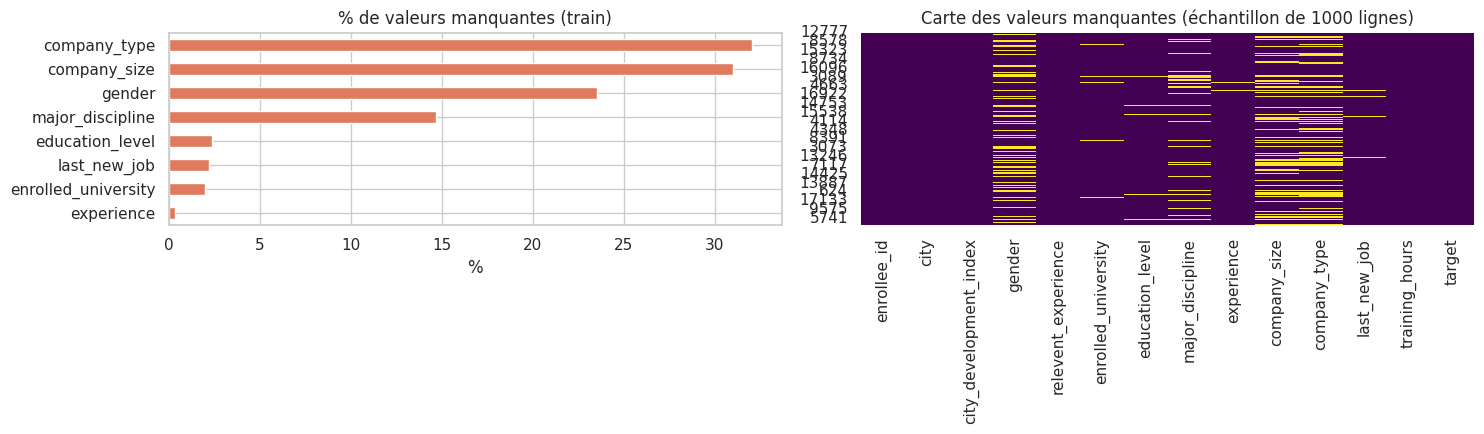

Lignes avec au moins une valeur manquante : 53.3%
→ supprimer ces lignes ferait perdre une grande partie des données : on imputera plutôt.


In [5]:
def missing_table(df):
    m = df.isna().sum()
    return (pd.DataFrame({"nb_manquants": m, "pct_manquants": (m / len(df) * 100).round(2)})
              .query("nb_manquants > 0").sort_values("pct_manquants", ascending=False))

miss = missing_table(train).join(missing_table(test), rsuffix="_test", how="outer").fillna(0)
display(miss)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
miss["pct_manquants"].sort_values().plot.barh(ax=axes[0], color="#e07a5f")
axes[0].set_title("% de valeurs manquantes (train)"); axes[0].set_xlabel("%")
sns.heatmap(train.isna().sample(min(1000, len(train)), random_state=0), cbar=False, ax=axes[1], cmap="viridis")
axes[1].set_title("Carte des valeurs manquantes (échantillon de 1000 lignes)")
plt.tight_layout(); plt.show()

print(f"Lignes avec au moins une valeur manquante : {train.isna().any(axis=1).mean():.1%}")
print("→ supprimer ces lignes ferait perdre une grande partie des données : on imputera plutôt.")

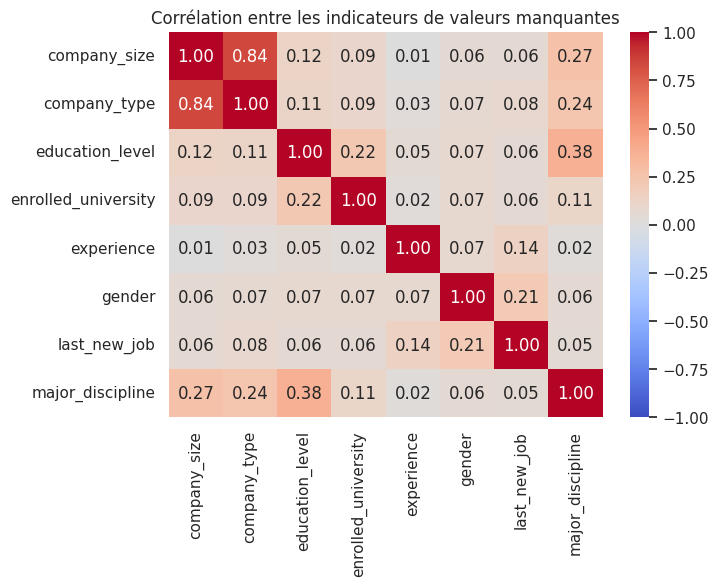

In [6]:
# Les valeurs manquantes apparaissent-elles ensemble ? (corrélation entre indicateurs de manque)
miss_cols = miss.index.tolist()
plt.figure(figsize=(7, 5))
sns.heatmap(train[miss_cols].isna().corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélation entre les indicateurs de valeurs manquantes")
plt.show()

### 2.3 Modalités des variables catégorielles et cohérence train/test

In [7]:
cat_cols = train.select_dtypes("object").columns.tolist()
for c in cat_cols:
    if c == "city":
        continue
    vals = train[c].value_counts(dropna=False)
    print(f"\n▶ {c} ({train[c].nunique()} modalités)")
    print(vals.to_string())

print("\n▶ city :", train["city"].nunique(), "villes distinctes (haute cardinalité)")
for c in cat_cols:
    only_test = set(test[c].dropna()) - set(train[c].dropna())
    if only_test:
        print(f"⚠ {c} : modalités présentes uniquement dans le test → {only_test}")


▶ gender (3 modalités)
gender
Male      13221
NaN        4508
Female     1238
Other       191

▶ relevent_experience (2 modalités)
relevent_experience
Has relevent experience    13792
No relevent experience      5366

▶ enrolled_university (3 modalités)
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386

▶ education_level (5 modalités)
education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School      308

▶ major_discipline (6 modalités)
major_discipline
STEM               14492
NaN                 2813
Humanities           669
Other                381
Business Degree      327
Arts                 253
No Major             223

▶ experience (22 modalités)
experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1     

**Points d'attention repérés :**
- `company_size` contient la modalité **`10/49`** alors que les autres tranches utilisent un tiret (`50-99`, `100-500`…) → format incohérent à harmoniser.
- `experience` et `last_new_job` sont des **nombres stockés en texte** avec des bornes ouvertes (`<1`, `>20`, `never`, `>4`) → à convertir en ordinal numérique.
- `company_size`, `education_level`, `enrolled_university` sont **ordinales** ; `gender`, `major_discipline`, `company_type` sont **nominales** ; `relevent_experience` est **binaire**.
- `city` a une **haute cardinalité** et est redondante en partie avec `city_development_index`.

In [8]:
# Cohérence logique : une ville = un seul indice de développement ?
cdi_per_city = train.groupby("city")["city_development_index"].nunique()
print("Villes ayant plusieurs city_development_index :", (cdi_per_city > 1).sum())

# Cohérence éducation / spécialité
display(pd.crosstab(train["education_level"].fillna("NaN"), train["major_discipline"].fillna("NaN")))

Villes ayant plusieurs city_development_index : 0


major_discipline,Arts,Business Degree,Humanities,NaN,No Major,Other,STEM
education_level,,,,,,,
Graduate,208,238,420,22,194,272,10244
High School,0,0,0,2017,0,0,0
Masters,42,86,225,6,29,100,3873
NaN,0,0,0,460,0,0,0
Phd,3,3,24,0,0,9,375
Primary School,0,0,0,308,0,0,0


> On observe généralement que les candidats de niveau `High School` / `Primary School` n'ont **pas de spécialité renseignée** : ce n'est pas une vraie valeur manquante, c'est une valeur **non applicable**. Ces cas seront imputés par `Not applicable` plutôt que par le mode.

## 3. Analyse univariée

### 3.1 Variable cible

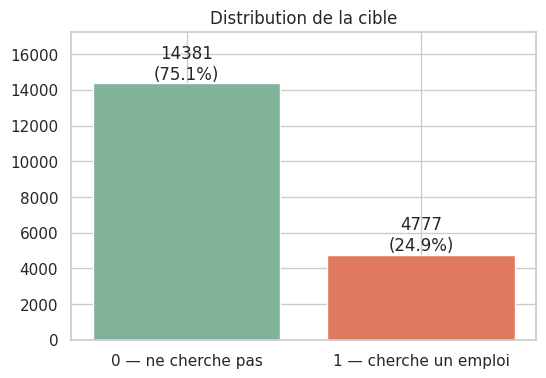

Ratio de déséquilibre : 3.01 pour 1


In [9]:
counts = train[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["0 — ne cherche pas", "1 — cherche un emploi"], counts.values, color=["#81b29a", "#e07a5f"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_title("Distribution de la cible"); ax.set_ylim(0, counts.max() * 1.2)
plt.show()
print(f"Ratio de déséquilibre : {counts[0] / counts[1]:.2f} pour 1")

> Le jeu est **déséquilibré** : pour la modélisation il faudra utiliser une validation **stratifiée**, des métriques adaptées (ROC-AUC, F1, rappel de la classe 1, PR-AUC) plutôt que l'accuracy, et éventuellement `class_weight="balanced"` ou du rééchantillonnage (SMOTE) **uniquement sur le train**.

### 3.2 Variables numériques

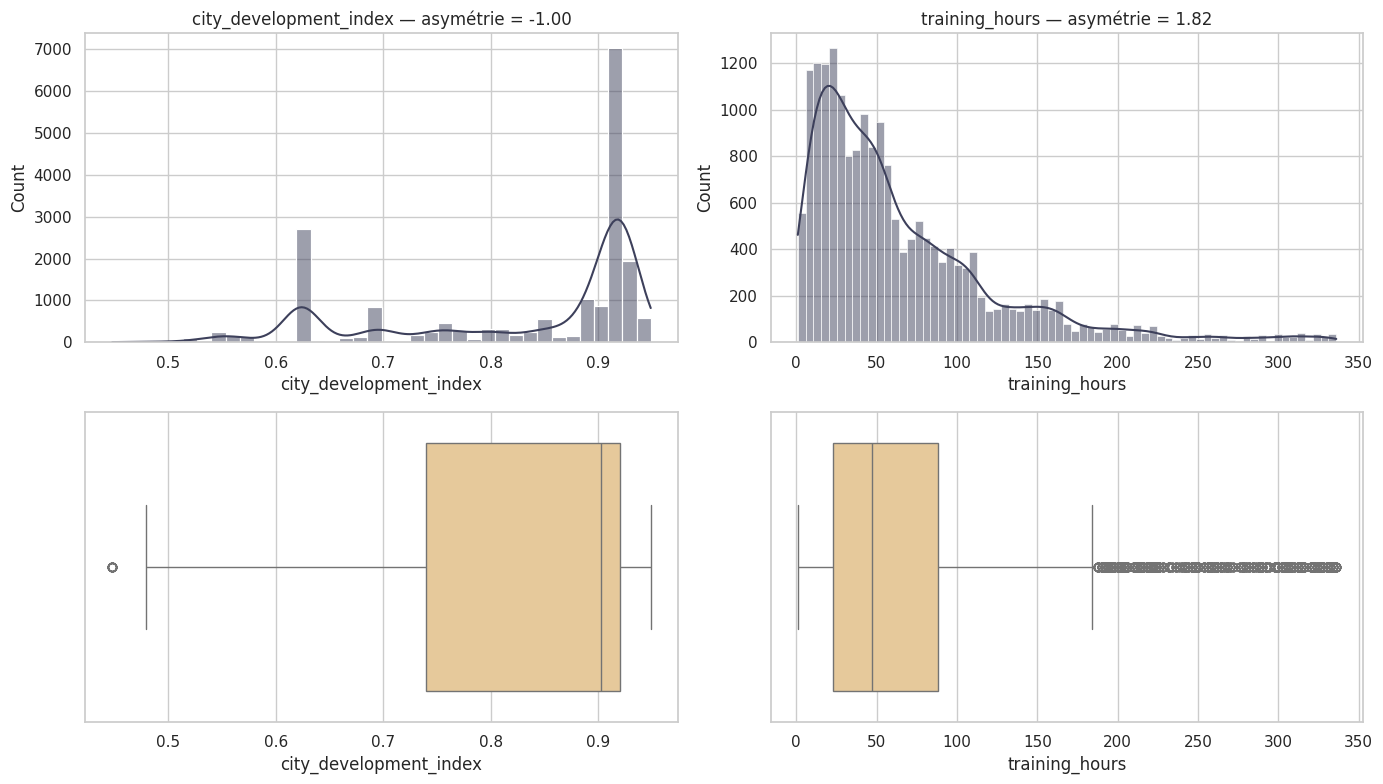

city_development_index    | outliers IQR :    17 (0.1%) | min=0.4479999999999999 max=0.949
training_hours            | outliers IQR :   984 (5.1%) | min=1 max=336


In [10]:
num_cols = ["city_development_index", "training_hours"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, c in enumerate(num_cols):
    sns.histplot(train[c], kde=True, ax=axes[0, i], color="#3d405b")
    axes[0, i].set_title(f"{c} — asymétrie = {train[c].skew():.2f}")
    sns.boxplot(x=train[c], ax=axes[1, i], color="#f2cc8f")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for c in num_cols:
    print(f"{c:25s} | outliers IQR : {iqr_outliers(train[c]):5d} ({iqr_outliers(train[c]) / len(train):.1%}) | min={train[c].min()} max={train[c].max()}")

> `training_hours` est fortement **asymétrique à droite** : les « outliers » au sens de l'IQR sont des valeurs réalistes (heures de formation élevées), pas des erreurs. On **ne les supprime pas** ; une transformation `log1p` réduira l'asymétrie pour les modèles linéaires.
> `city_development_index` est **multimodal** : il reflète quelques grandes villes très représentées.

### 3.3 Variables catégorielles

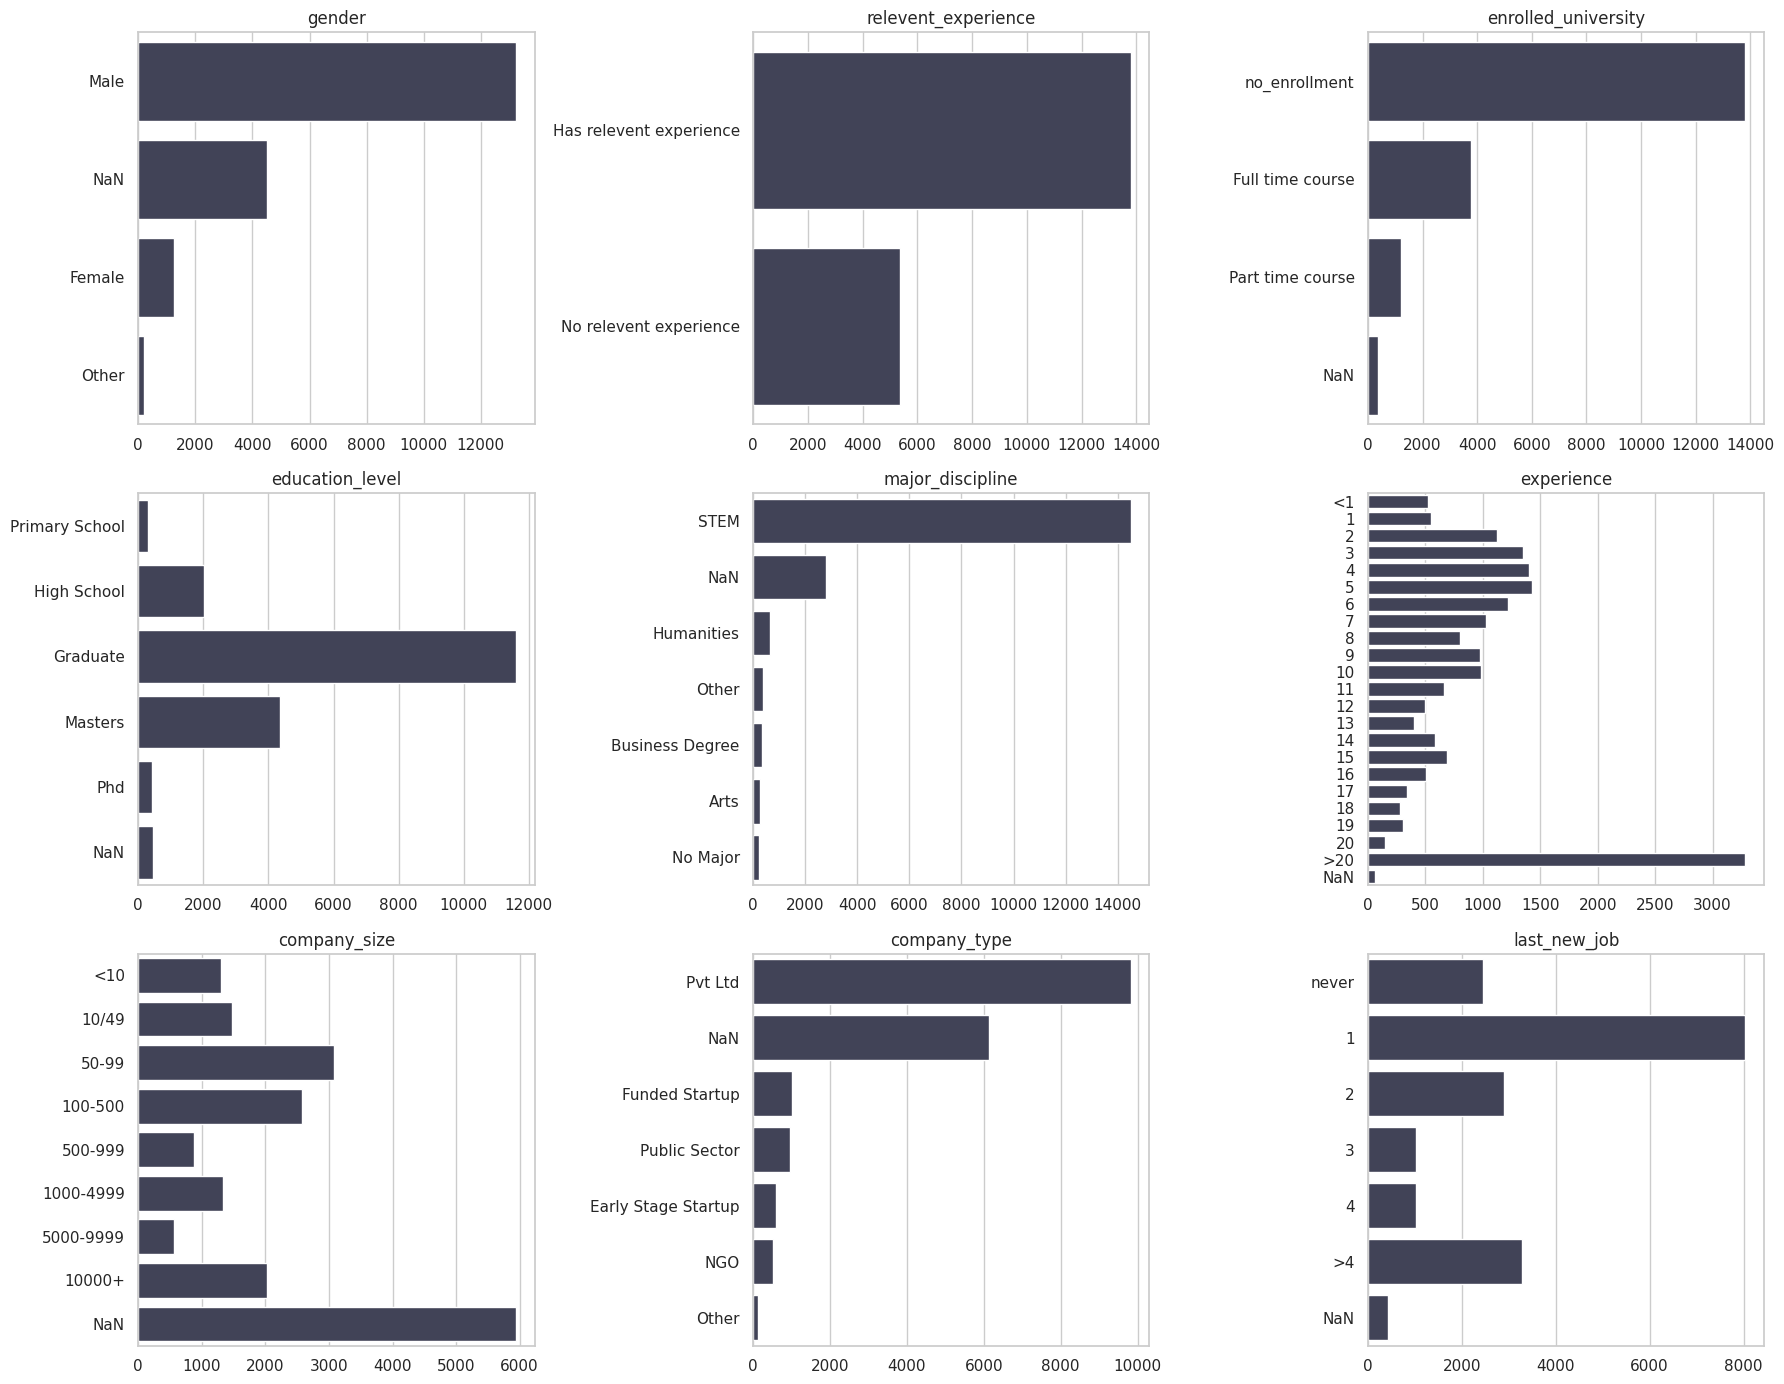

In [11]:
plot_cats = ["gender", "relevent_experience", "enrolled_university", "education_level",
             "major_discipline", "experience", "company_size", "company_type", "last_new_job"]
order_map = {
    "experience": ["<1"] + [str(i) for i in range(1, 21)] + [">20"],
    "company_size": ["<10", "10/49", "50-99", "100-500", "500-999", "1000-4999", "5000-9999", "10000+"],
    "last_new_job": ["never", "1", "2", "3", "4", ">4"],
    "education_level": ["Primary School", "High School", "Graduate", "Masters", "Phd"],
}
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, c in zip(axes.flat, plot_cats):
    s = train[c].fillna("NaN")
    order = [o for o in order_map.get(c, s.value_counts().index) if o in s.unique()]
    if "NaN" in s.unique() and "NaN" not in order:
        order.append("NaN")
    sns.countplot(y=s, order=order, ax=ax, color="#3d405b")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Top 10 villes = 66.3% des candidats
Villes avec moins de 20 candidats : 44 / 123


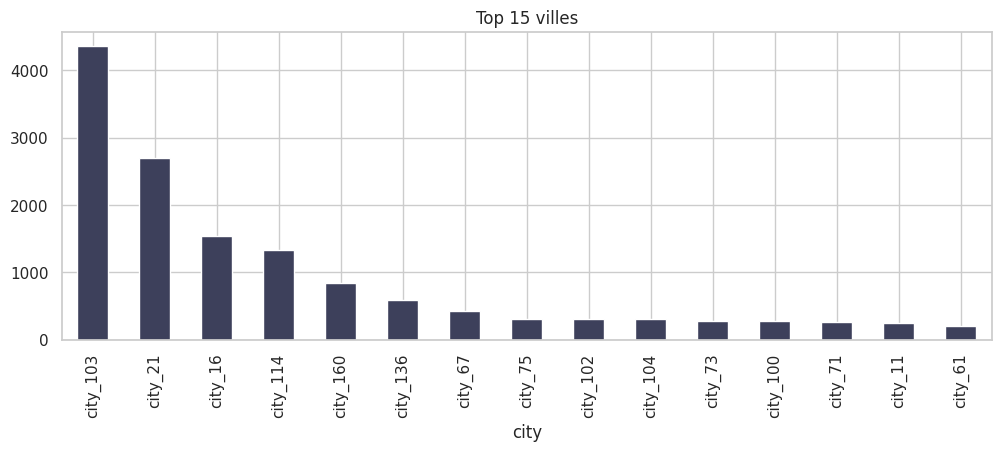

In [12]:
# Ville : très forte concentration sur quelques villes
city_counts = train["city"].value_counts()
print(f"Top 10 villes = {city_counts.head(10).sum() / len(train):.1%} des candidats")
print(f"Villes avec moins de 20 candidats : {(city_counts < 20).sum()} / {len(city_counts)}")
city_counts.head(15).plot.bar(figsize=(12, 4), color="#3d405b", title="Top 15 villes"); plt.show()

## 4. Analyse bivariée : quels facteurs sont liés au changement d'emploi ?

### 4.1 Taux de recherche d'emploi par modalité

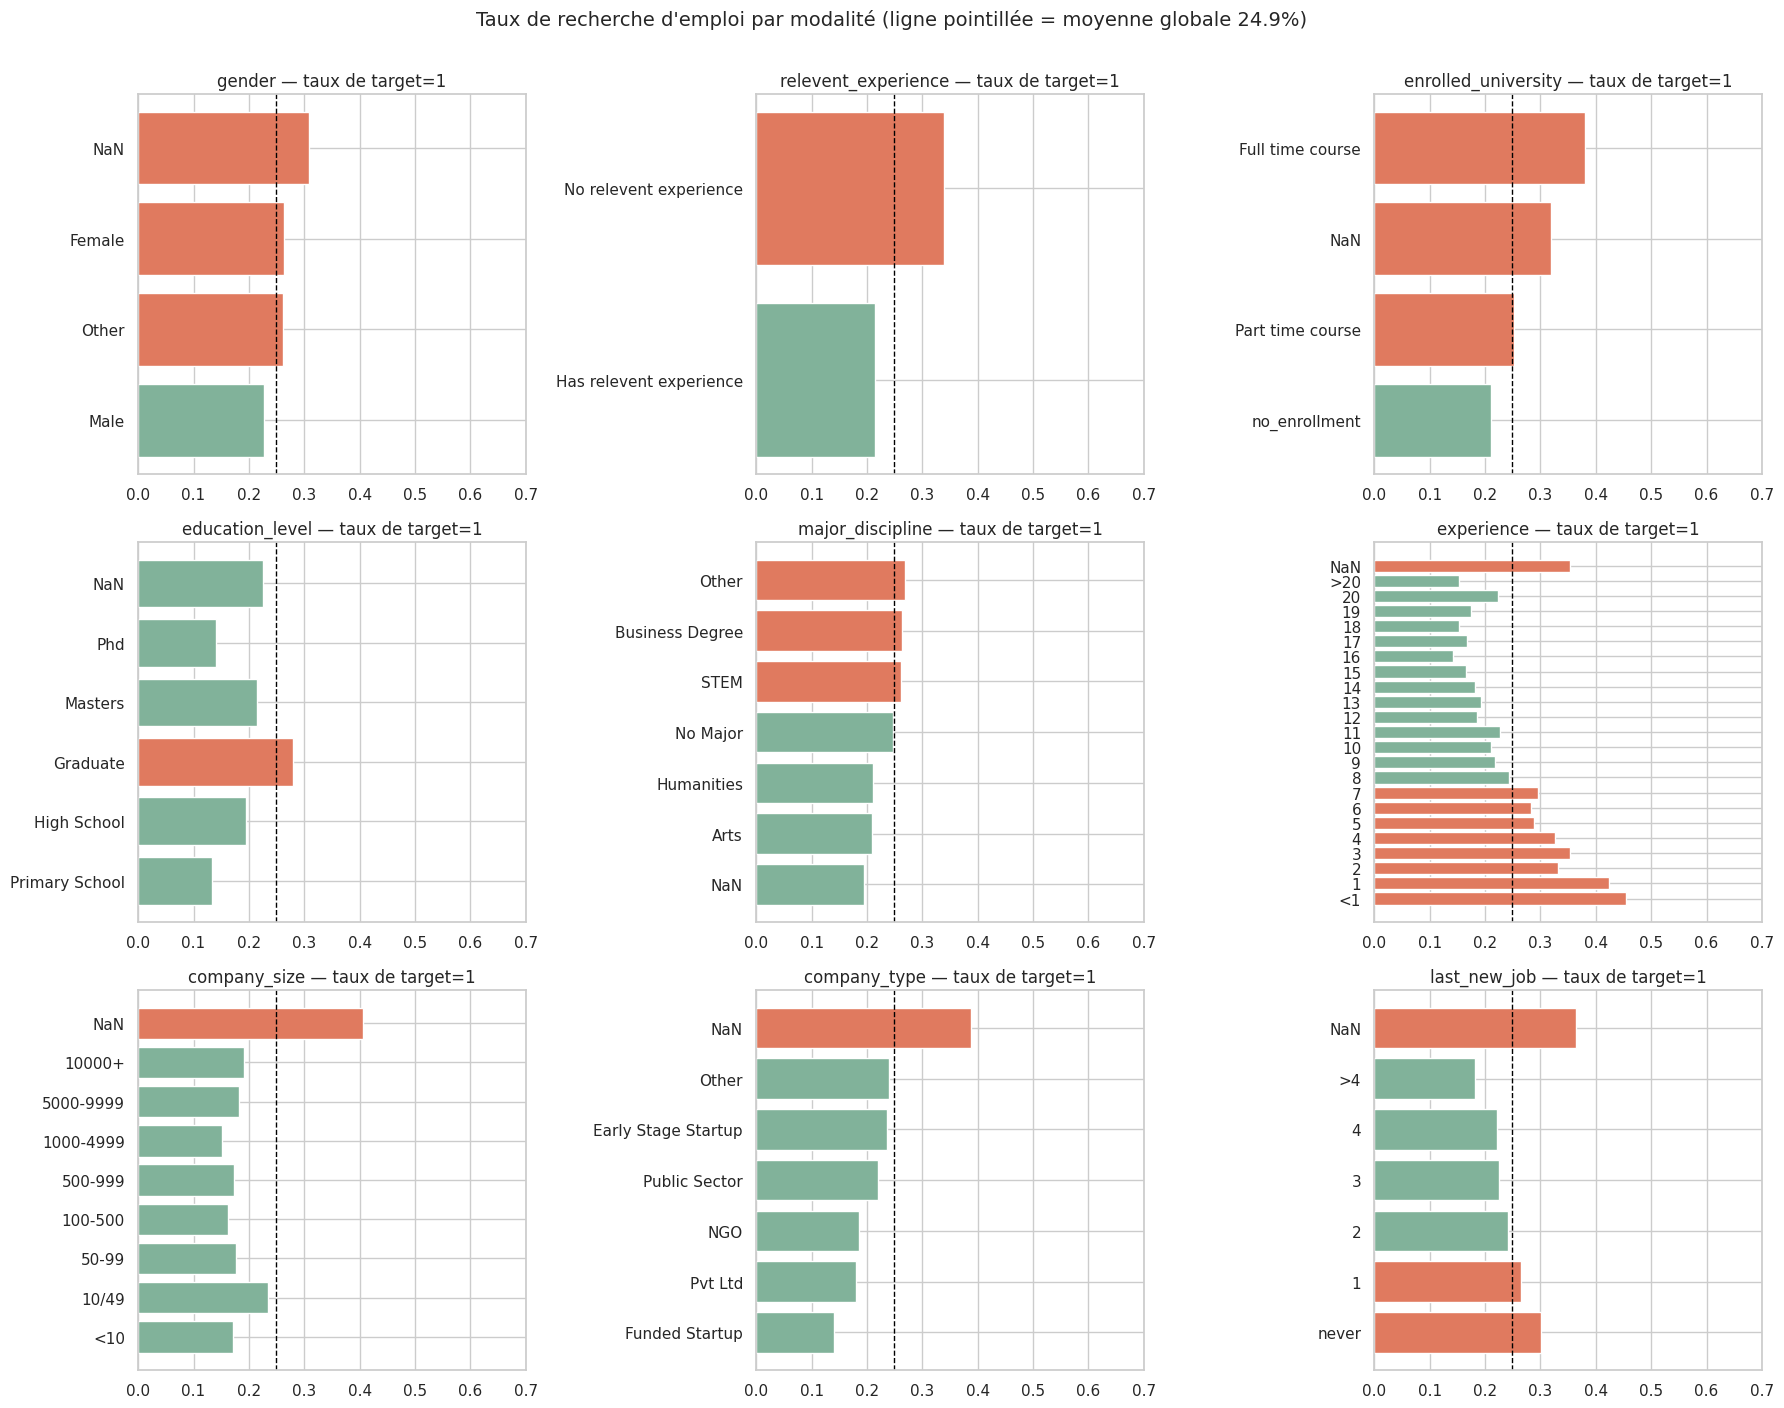

In [13]:
global_rate = train[TARGET].mean()
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, c in zip(axes.flat, plot_cats):
    s = train[c].fillna("NaN")
    g = train.assign(**{c: s}).groupby(c)[TARGET].agg(["mean", "size"])
    order = [o for o in order_map.get(c, g.sort_values("mean").index) if o in g.index]
    if "NaN" in g.index and "NaN" not in order:
        order.append("NaN")
    g = g.loc[order]
    ax.barh(g.index.astype(str), g["mean"], color=["#e07a5f" if m > global_rate else "#81b29a" for m in g["mean"]])
    ax.axvline(global_rate, ls="--", c="k", lw=1)
    ax.set_title(f"{c} — taux de target=1"); ax.set_xlim(0, max(0.7, g["mean"].max() * 1.1))
fig.suptitle(f"Taux de recherche d'emploi par modalité (ligne pointillée = moyenne globale {global_rate:.1%})", y=1.005, fontsize=14)
plt.tight_layout(); plt.show()

### 4.2 Force de l'association : test du χ² et V de Cramér

,variable,cramers_v,chi2,p_value,significatif (5%)
0,city,0.388,2998.8,0.000000e+00,True
1,company_size,0.245,1162.0,1.587453e-245,True
2,company_type,0.223,959.8,4.351920e-204,True
3,experience,0.189,704.7,7.882248e-135,True
4,enrolled_university,0.155,463.5,3.809312e-100,True
5,relevent_experience,0.128,315.3,1.500663e-70,True
6,education_level,0.092,167.3,2.787357e-34,True
7,last_new_job,0.090,162.0,2.244940e-32,True
8,gender,0.077,117.4,2.833049e-25,True
9,major_discipline,0.055,64.2,6.224537e-12,True


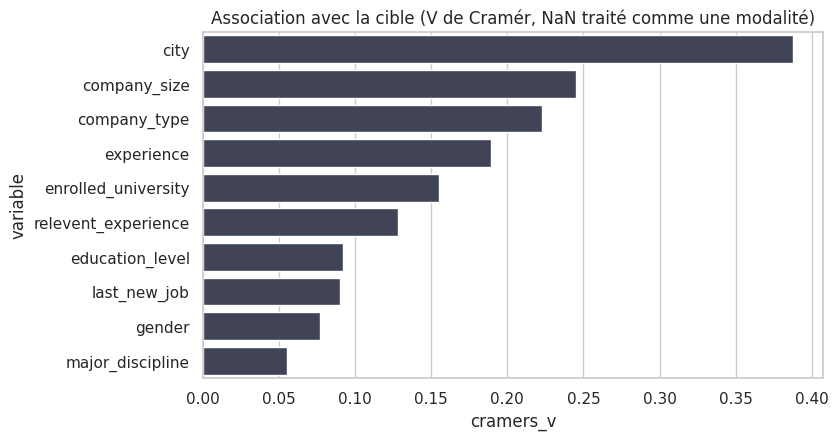

In [14]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    # correction de biais (Bergsma 2013)
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-9, min(kc - 1, rc - 1))), chi2, p

rows = []
for c in plot_cats + ["city"]:
    v, chi2, p = cramers_v(train[c].fillna("NaN"), train[TARGET])
    rows.append({"variable": c, "cramers_v": round(v, 3), "chi2": round(chi2, 1), "p_value": p})
assoc_cat = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
assoc_cat["significatif (5%)"] = assoc_cat["p_value"] < 0.05
display(assoc_cat)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=assoc_cat, x="cramers_v", y="variable", color="#3d405b")
plt.title("Association avec la cible (V de Cramér, NaN traité comme une modalité)"); plt.show()

### 4.3 Variables numériques vs cible

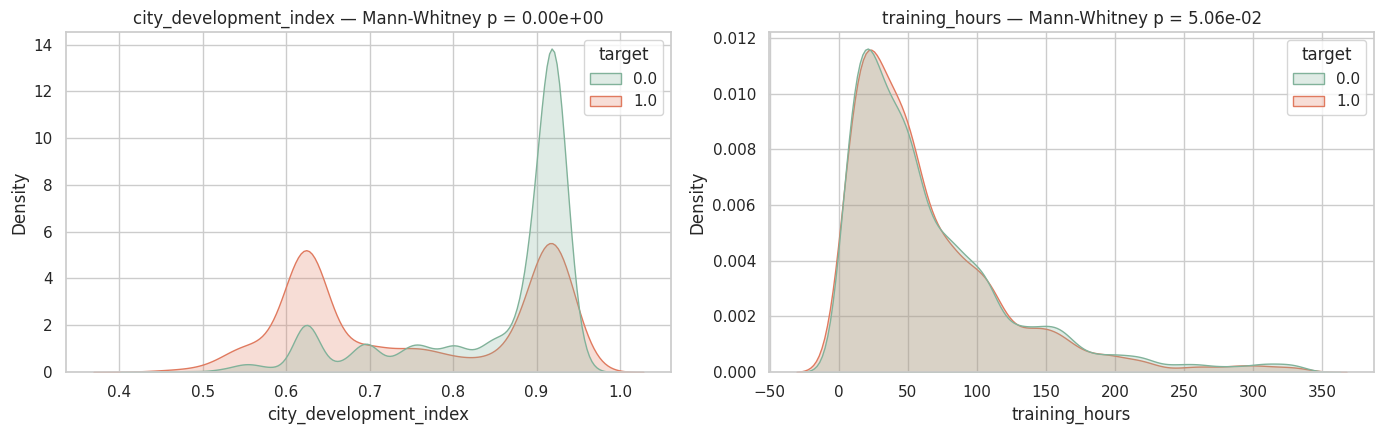

,city_development_index,training_hours
target,,
médiane target=0,0.91,48.0
médiane target=1,0.74,46.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=train, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax, palette=["#81b29a", "#e07a5f"])
    u, p = stats.mannwhitneyu(train.loc[train[TARGET] == 0, c], train.loc[train[TARGET] == 1, c])
    ax.set_title(f"{c} — Mann-Whitney p = {p:.2e}")
plt.tight_layout(); plt.show()
display(train.groupby(TARGET)[num_cols].median().rename(index={0: "médiane target=0", 1: "médiane target=1"}))

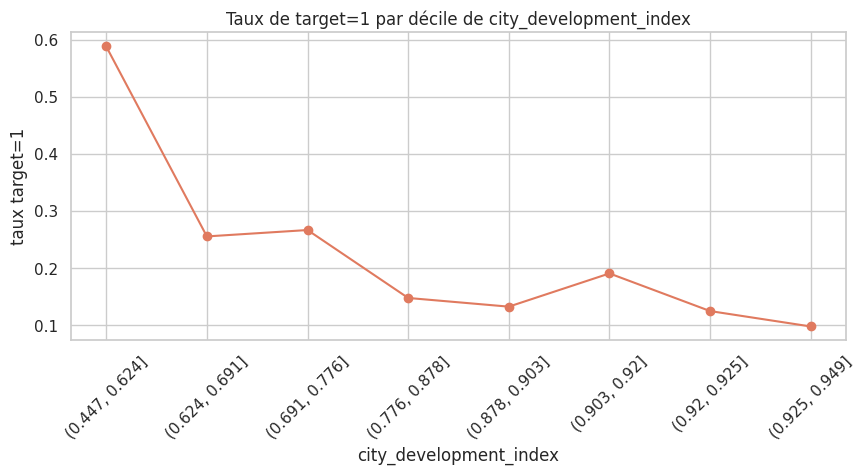

In [16]:
# Relation fine entre le développement de la ville et la cible
cdi_bins = pd.qcut(train["city_development_index"], q=10, duplicates="drop")
train.groupby(cdi_bins)[TARGET].mean().plot(marker="o", figsize=(10, 4), color="#e07a5f",
    title="Taux de target=1 par décile de city_development_index")
plt.xticks(rotation=45); plt.ylabel("taux target=1"); plt.show()

### 4.4 Interactions intéressantes

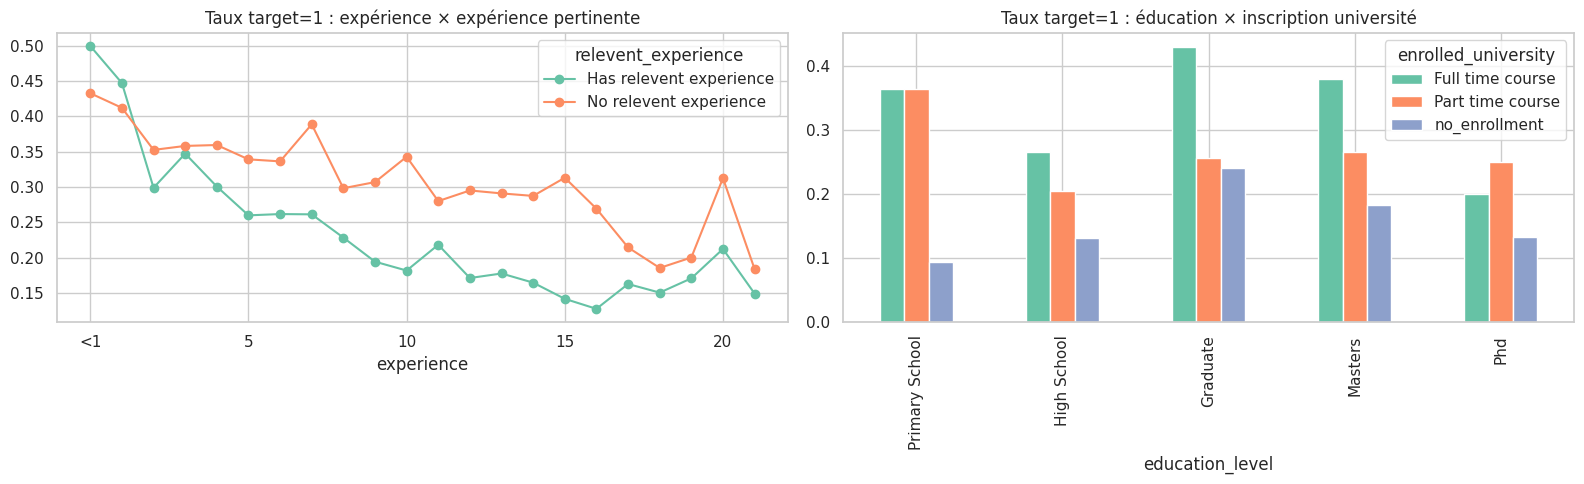

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pd.crosstab(train["experience"], train["relevent_experience"], values=train[TARGET], aggfunc="mean") \
  .reindex(order_map["experience"]).plot(ax=axes[0], marker="o", title="Taux target=1 : expérience × expérience pertinente")
pd.crosstab(train["education_level"], train["enrolled_university"], values=train[TARGET], aggfunc="mean") \
  .reindex(order_map["education_level"]).plot.bar(ax=axes[1], title="Taux target=1 : éducation × inscription université")
plt.tight_layout(); plt.show()

## 5. Les valeurs manquantes sont-elles informatives ?

In [18]:
rows = []
for c in miss_cols:
    if c not in train.columns: continue
    is_na = train[c].isna()
    if is_na.sum() == 0: continue
    rows.append({"variable": c,
                 "taux_target_si_manquant": train.loc[is_na, TARGET].mean(),
                 "taux_target_si_renseigne": train.loc[~is_na, TARGET].mean(),
                 "p_value_chi2": stats.chi2_contingency(pd.crosstab(is_na, train[TARGET]))[1]})
na_info = pd.DataFrame(rows)
na_info["écart"] = na_info["taux_target_si_manquant"] - na_info["taux_target_si_renseigne"]
display(na_info.sort_values("écart", key=abs, ascending=False).style.format(
    {"taux_target_si_manquant": "{:.1%}", "taux_target_si_renseigne": "{:.1%}", "écart": "{:+.1%}", "p_value_chi2": "{:.2e}"}))

,variable,taux_target_si_manquant,taux_target_si_renseigne,p_value_chi2,écart
0,company_size,40.6%,17.9%,1.22e-246,+22.7%
1,company_type,38.8%,18.4%,2.13e-204,+20.4%
6,last_new_job,36.4%,24.7%,4.82e-08,+11.7%
4,experience,35.4%,24.9%,7.08e-02,+10.5%
5,gender,30.8%,23.1%,2.22e-25,+7.7%
3,enrolled_university,31.9%,24.8%,1.81e-03,+7.1%
7,major_discipline,19.5%,25.9%,7.63e-13,-6.4%
2,education_level,22.6%,25.0%,2.66e-01,-2.4%


> Si le taux de `target=1` diffère nettement entre lignes manquantes et renseignées (p-value faible), les données sont **non manquantes au hasard (MNAR)** : le fait de ne pas renseigner son entreprise, par exemple, peut indiquer qu'on n'est pas en poste.
> **Conséquence pour le nettoyage :** pour ces variables, on n'impute pas « en aveugle » par le mode — on crée une modalité `Unknown` et/ou une **colonne indicatrice** `<var>_missing` pour conserver ce signal.

## 6. Nettoyage et transformation

**Stratégie retenue** (toutes les règles sont apprises sur le **train** puis appliquées au **test**, pour éviter toute fuite d'information) :

| Étape | Variables | Action |
|---|---|---|
| Harmonisation | `company_size` | `10/49` → `10-49` |
| Valeur non applicable | `major_discipline` | NaN + niveau `Primary/High School` → `Not applicable` |
| Indicateurs de manque | `gender`, `major_discipline`, `company_size`, `company_type`, `enrolled_university`, `last_new_job` | colonnes binaires `*_missing` (manques informatifs, p < 0,05 en section 5) |
| Binaire | `relevent_experience` | 1 / 0 |
| Ordinal | `experience`, `last_new_job`, `company_size`, `education_level`, `enrolled_university` | conversion en entiers ordonnés, NaN → médiane du train |
| Nominal | `gender`, `major_discipline`, `company_type` | NaN → `Unknown`, puis one-hot |
| Haute cardinalité | `city` | regroupement des villes rares + encodage par fréquence |
| Asymétrie | `training_hours` | `log1p` |
| Manque combiné | `company_size` + `company_type` | indicateur `no_company_info` (40 % de target=1 vs 18 %) |
| Effet de seuil | `city_development_index` | `low_cdi` (≤ 0,625) et `cdi_bin` (4 tranches) |
| Non monotone | `company_size`, `education_level` | ordinal + version one-hot `*_cat_*` |
| Variable sensible | `gender` | conservée pour l'analyse, exclue du modèle (`SENSITIVE_COLS`) |

In [19]:
EXPERIENCE_MAP = {"<1": 0, **{str(i): i for i in range(1, 21)}, ">20": 21}
LAST_NEW_JOB_MAP = {"never": 0, "1": 1, "2": 2, "3": 3, "4": 4, ">4": 5}
COMPANY_SIZE_MAP = {"<10": 0, "10-49": 1, "50-99": 2, "100-500": 3, "500-999": 4,
                    "1000-4999": 5, "5000-9999": 6, "10000+": 7}
EDUCATION_MAP = {"Primary School": 0, "High School": 1, "Graduate": 2, "Masters": 3, "Phd": 4}
ENROLLED_MAP = {"no_enrollment": 0, "Part time course": 1, "Full time course": 2}
REL_EXP_MAP = {"Has relevent experience": 1, "No relevent experience": 0}

ORDINAL_MAPS = {"experience": EXPERIENCE_MAP, "last_new_job": LAST_NEW_JOB_MAP,
                "company_size": COMPANY_SIZE_MAP, "education_level": EDUCATION_MAP,
                "enrolled_university": ENROLLED_MAP}
NOMINAL_COLS = ["gender", "major_discipline", "company_type"]
# Variables ordinales dont la relation à la cible n'est PAS monotone (section 4.1)
# → on ajoute aussi une version one-hot, utile pour les modèles linéaires
NON_MONOTONIC_COLS = ["company_size", "education_level"]
# Indicateurs de manque uniquement pour les manques informatifs (section 5, p < 0.05)
# education_level (p=0.27) et experience (p=0.07, 65 lignes) sont retirés
MISSING_FLAG_COLS = ["gender", "major_discipline", "company_size", "company_type",
                     "enrolled_university", "last_new_job"]
RARE_CITY_THRESHOLD = 20
LOW_CDI_THRESHOLD = 0.625   # 1er décile : 59 % de target=1 contre ~10-25 % ailleurs (section 4.3)
SENSITIVE_COLS = None       # rempli après transformation : colonnes gender_* à exclure du modèle


class HRCleaner:
    """Nettoyage reproductible : fit sur le train, transform sur train et test."""

    def _harmonize(self, df):
        df = df.copy()
        for c in df.select_dtypes("object").columns:
            df[c] = df[c].str.strip()
        df["company_size"] = df["company_size"].replace({"10/49": "10-49"})
        # 2 785 des 2 813 NaN de major_discipline sont des niveaux pré-universitaires (section 2.3)
        mask = df["major_discipline"].isna() & df["education_level"].isin(["Primary School", "High School"])
        df.loc[mask, "major_discipline"] = "Not applicable"
        return df

    def fit(self, df):
        df = self._harmonize(df)
        self.ord_medians_ = {c: df[c].map(m).median() for c, m in ORDINAL_MAPS.items()}
        city_counts = df["city"].value_counts()
        self.frequent_cities_ = set(city_counts[city_counts >= RARE_CITY_THRESHOLD].index)
        grouped = df["city"].where(df["city"].isin(self.frequent_cities_), "rare_city")
        self.city_freq_ = grouped.value_counts(normalize=True).to_dict()
        self.cdi_median_ = df["city_development_index"].median()
        self.th_median_ = df["training_hours"].median()
        self.nominal_levels_ = {c: sorted(df[c].fillna("Unknown").unique())
                                for c in NOMINAL_COLS + NON_MONOTONIC_COLS}
        return self

    def transform(self, df):
        df = self._harmonize(df)
        out = pd.DataFrame(index=df.index)
        out["enrollee_id"] = df["enrollee_id"]

        # Indicateurs de manque (avant imputation)
        for c in MISSING_FLAG_COLS:
            out[f"{c}_missing"] = df[c].isna().astype(int)
        # Taille ET type d'entreprise manquants ensemble (corr = 0.84) : ~40 % de target=1 contre 18 %
        out["no_company_info"] = (df["company_size"].isna() & df["company_type"].isna()).astype(int)

        # Numériques
        out["city_development_index"] = df["city_development_index"].fillna(self.cdi_median_)
        out["low_cdi"] = (out["city_development_index"] <= LOW_CDI_THRESHOLD).astype(int)
        out["cdi_bin"] = pd.cut(out["city_development_index"],
                                bins=[0, 0.625, 0.775, 0.9, 1.0], labels=False, include_lowest=True)
        out["training_hours"] = df["training_hours"].fillna(self.th_median_)
        out["training_hours_log"] = np.log1p(out["training_hours"])

        # Ville : regroupement des rares + fréquence
        city = df["city"].where(df["city"].isin(self.frequent_cities_), "rare_city")
        out["city_grouped"] = city
        out["city_freq"] = city.map(self.city_freq_).fillna(0)

        # Binaire
        out["relevent_experience"] = df["relevent_experience"].map(REL_EXP_MAP)

        # Ordinales (NaN → médiane du train ; l'info du manque est gardée dans *_missing)
        for c, m in ORDINAL_MAPS.items():
            out[c] = df[c].map(m).fillna(self.ord_medians_[c]).astype(int)

        # One-hot : nominales + ordinales non monotones (avec modalité Unknown)
        for c in NOMINAL_COLS + NON_MONOTONIC_COLS:
            s = df[c].fillna("Unknown")
            s = s.where(s.isin(self.nominal_levels_[c]), "Unknown")
            prefix = f"{c}_cat" if c in NON_MONOTONIC_COLS else c
            for lvl in self.nominal_levels_[c]:
                out[f"{prefix}_{lvl}".replace(" ", "_")] = (s == lvl).astype(int)

        # Features dérivées
        out["exp_minus_last_job"] = out["experience"] - out["last_new_job"]
        out["is_student"] = (out["enrolled_university"] > 0).astype(int)
        out["n_missing"] = df[MISSING_FLAG_COLS].isna().sum(axis=1)

        if TARGET in df.columns:
            out[TARGET] = df[TARGET].astype(int)
        return out


cleaner = HRCleaner().fit(train)
train_clean = cleaner.transform(train)
test_clean = cleaner.transform(test)
SENSITIVE_COLS = [c for c in train_clean.columns if c.startswith("gender")]
print("Train nettoyé :", train_clean.shape, "| Test nettoyé :", test_clean.shape)
print("Colonnes sensibles à exclure de la modélisation :", SENSITIVE_COLS)
train_clean.head()

Train nettoyé : (19158, 59) | Test nettoyé : (2129, 58)
Colonnes sensibles à exclure de la modélisation : ['gender_missing', 'gender_Female', 'gender_Male', 'gender_Other', 'gender_Unknown']


,enrollee_id,gender_missing,major_discipline_missing,company_size_missing,company_type_missing,enrolled_university_missing,last_new_job_missing,no_company_info,city_development_index,low_cdi,cdi_bin,training_hours,training_hours_log,city_grouped,city_freq,relevent_experience,experience,last_new_job,company_size,education_level,enrolled_university,gender_Female,gender_Male,gender_Other,gender_Unknown,...,company_type_Funded_Startup,company_type_NGO,company_type_Other,company_type_Public_Sector,company_type_Pvt_Ltd,company_type_Unknown,company_size_cat_10-49,company_size_cat_100-500,company_size_cat_1000-4999,company_size_cat_10000+,company_size_cat_50-99,company_size_cat_500-999,company_size_cat_5000-9999,company_size_cat_<10,company_size_cat_Unknown,education_level_cat_Graduate,education_level_cat_High_School,education_level_cat_Masters,education_level_cat_Phd,education_level_cat_Primary_School,education_level_cat_Unknown,exp_minus_last_job,is_student,n_missing,target
0,8949,0,0,1,1,0,0,1,0.920,0,3,36,3.610918,city_103,0.227320,1,21,1,3,2,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,20,0,2,1
1,29725,0,0,0,0,0,0,0,0.776,0,2,47,3.871201,city_40,0.003549,0,15,5,2,2,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,10,0,0,0
2,11561,1,0,1,1,0,0,1,0.624,1,0,83,4.430817,city_21,0.141038,0,5,0,3,2,2,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,5,1,3,0
3,33241,1,0,1,0,1,0,0,0.789,0,2,52,3.970292,city_115,0.002819,0,0,0,3,2,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,3,1
4,666,0,0,0,0,0,0,0,0.767,0,1,8,2.197225,city_162,0.006681,1,21,4,2,3,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,17,0,0,0


In [20]:
# Version « lisible » (catégorielles imputées mais non encodées) — utile pour l'analyse et pour CatBoost
def readable_clean(df):
    d = cleaner._harmonize(df)
    for c in NOMINAL_COLS:
        d[c] = d[c].fillna("Unknown")
    for c in ORDINAL_MAPS:
        d[c] = d[c].fillna("Unknown")
    d["city"] = d["city"].where(d["city"].isin(cleaner.frequent_cities_), "rare_city")
    return d

train_readable = readable_clean(train)
test_readable = readable_clean(test)

**Résultat du nettoyage :** 19 158 lignes conservées (aucune suppression), 59 colonnes en train et 58 en test (sans la cible).
Les 5 colonnes liées au genre sont identifiées comme sensibles : elles restent disponibles pour l'analyse mais seront exclues de la modélisation, car leur pouvoir prédictif est faible (V de Cramér = 0,077) et leur usage pour sélectionner des candidats poserait un problème éthique et légal.

À noter : après le nettoyage, `major_discipline_missing` ne signale plus que 488 lignes (contre 2 813 avant), puisque les 2 325 candidats de niveau lycée ou primaire ont été reclassés en « Not applicable ». Il reste donc surtout les candidats dont le niveau d'éducation est lui-même inconnu (460).

## 7. Vérifications après nettoyage

In [22]:
assert train_clean.drop(columns=["city_grouped"]).isna().sum().sum() == 0, "Il reste des NaN dans le train !"
assert test_clean.drop(columns=["city_grouped"]).isna().sum().sum() == 0, "Il reste des NaN dans le test !"
feature_cols = [c for c in train_clean.columns if c not in ["enrollee_id", TARGET, "city_grouped"]]
assert list(test_clean[feature_cols].columns) == feature_cols, "Colonnes train/test non alignées"
assert len(train_clean) == len(train) and len(test_clean) == len(test), "Des lignes ont été perdues"
print("✔ Aucune valeur manquante, colonnes alignées, aucune ligne perdue.")
print(f"✔ {len(feature_cols)} variables prêtes pour la modélisation.")

✔ Aucune valeur manquante, colonnes alignées, aucune ligne perdue.
✔ 56 variables prêtes pour la modélisation.


**Vérification :** aucune valeur manquante ne subsiste, les colonnes du train et du test sont identiques et dans le même ordre, et aucune ligne n'a été perdue. Les 56 variables obtenues sont entièrement numériques et prêtes pour la modélisation.

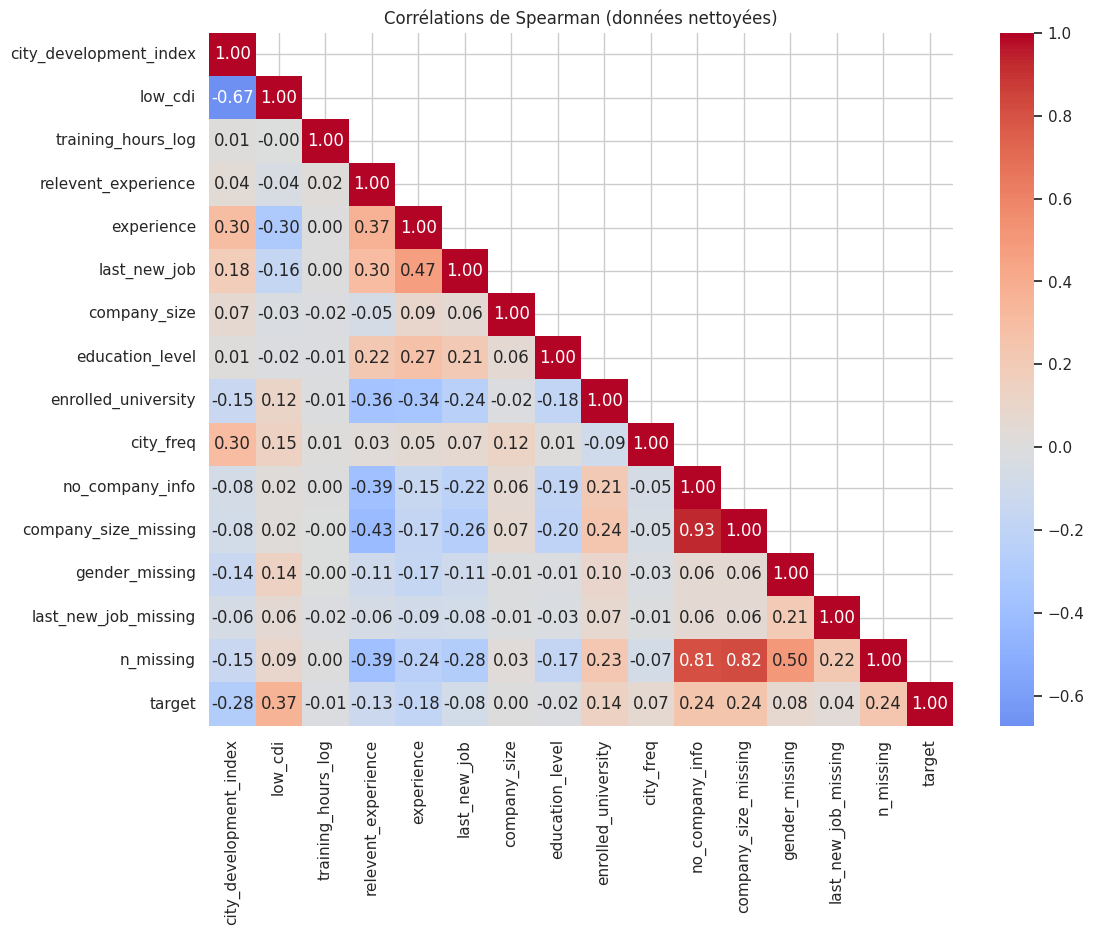

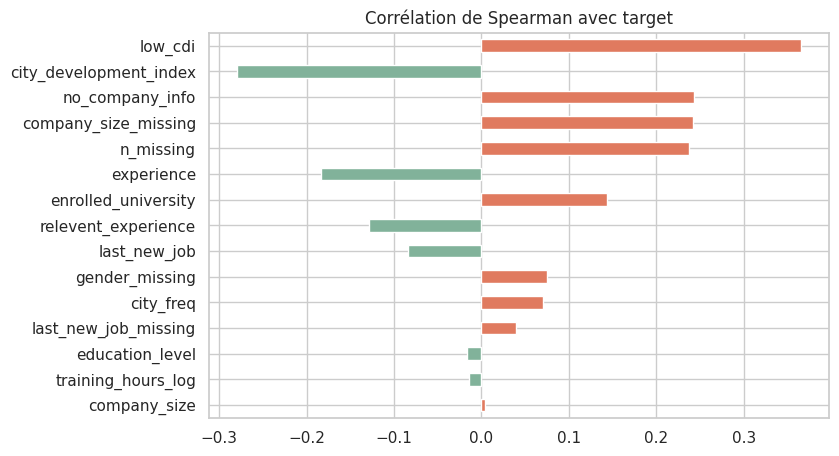

In [23]:
# Corrélations de Spearman (adaptée aux variables ordinales) avec la cible
core = ["city_development_index", "low_cdi", "training_hours_log", "relevent_experience", "experience",
        "last_new_job", "company_size", "education_level", "enrolled_university", "city_freq",
        "no_company_info", "company_size_missing", "gender_missing", "last_new_job_missing",
        "n_missing", TARGET]
corr = train_clean[core].corr(method="spearman")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Corrélations de Spearman (données nettoyées)"); plt.show()

corr_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_target.plot.barh(figsize=(8, 5), color=["#e07a5f" if v > 0 else "#81b29a" for v in corr_target],
                      title="Corrélation de Spearman avec target").invert_yaxis(); plt.show()

**Corrélations avec la cible (Spearman) :**
- **`low_cdi` (ρ = +0,37) est la variable la plus liée à la cible**, devant le `city_development_index` brut (ρ = −0,28). Ce gain confirme l'effet de seuil observé en section 4.3 : le risque de changement d'emploi est surtout concentré dans les villes les moins développées (≤ 0,625), et l'indicateur binaire capte mieux cette relation non linéaire que la variable continue.
- **`no_company_info` et `company_size_missing` (ρ = +0,24)** : ne pas renseigner son entreprise est le deuxième signal le plus fort. Ces candidats sont probablement sans emploi ou en transition, donc plus enclins à chercher un poste.
- **`n_missing` (ρ = +0,24)** n'apporte pas d'information nouvelle : il est corrélé à 0,81–0,82 aux indicateurs d'entreprise manquante, qui expliquent l'essentiel de son effet.
- **`experience` (ρ = −0,18), `relevent_experience` (−0,13), `last_new_job` (−0,08)** : plus un candidat est expérimenté et stable, moins il cherche à changer.
- **`enrolled_university` (ρ = +0,14)** : les étudiants, surtout à temps plein, sont davantage en recherche d'emploi.
- **`company_size` (ρ = 0,00) et `education_level` (ρ = −0,02)** ont une corrélation quasi nulle, ce qui ne veut pas dire qu'ils sont sans effet. Leur relation à la cible n'est **pas monotone** (section 4.1), et Spearman ne mesure que les relations monotones. C'est ce qui justifie leur version one-hot.
- **`training_hours` (ρ = −0,01)** n'a aucun lien avec la cible : le nombre d'heures de formation ne distingue pas les candidats qui veulent partir.

**Corrélations entre variables :** un profil « junior / étudiant » se dessine. Les candidats sans expérience pertinente sont plus souvent inscrits à l'université (ρ = −0,36) et n'ont souvent pas d'entreprise renseignée (ρ = −0,43 avec `company_size_missing`). Cela renforce l'hypothèse que les données d'entreprise manquent parce que ces candidats ne sont pas en poste.

**Limite :** aucune variable ne dépasse |ρ| = 0,37. Aucun facteur pris seul ne permet donc de prédire la décision : il faudra un modèle combinant plusieurs variables, et l'on peut s'attendre à des performances modérées.

In [24]:
# Multicolinéarité : paires de variables très corrélées
num_feats = train_clean[feature_cols]
c = num_feats.corr().abs().where(np.triu(np.ones((len(feature_cols),) * 2, dtype=bool), k=1)).stack()
print("Paires avec |corrélation| > 0.7 :")
print(c[c > 0.7].sort_values(ascending=False).to_string() or "aucune")

Paires avec |corrélation| > 0.7 :
gender_missing                   gender_Unknown                     1.000000
major_discipline_missing         major_discipline_Unknown           1.000000
company_size_missing             company_size_cat_Unknown           1.000000
company_type_missing             company_type_Unknown               1.000000
experience                       exp_minus_last_job                 0.971338
major_discipline_Unknown         education_level_cat_Unknown        0.970160
major_discipline_missing         education_level_cat_Unknown        0.970160
city_development_index           cdi_bin                            0.968170
enrolled_university              is_student                         0.962255
company_size_missing             no_company_info                    0.929972
no_company_info                  company_size_cat_Unknown           0.929972
major_discipline_Not_applicable  education_level_cat_High_School    0.923005
no_company_info                  company_t

**Multicolinéarité :** 31 paires dépassent |r| > 0,7. C'est attendu et cela ne révèle pas d'erreur : ces redondances viennent de la façon dont les variables ont été construites.
1. **Doublons exacts (r = 1)** : chaque `*_missing` est identique à la modalité `*_Unknown` de la même variable (genre, spécialité, taille et type d'entreprise). C'est la même information encodée deux fois.
2. **Variables dérivées de leur source** : `exp_minus_last_job` et `experience` (0,97), `is_student` et `enrolled_university` (0,96), `cdi_bin` et `city_development_index` (0,97), `training_hours` et sa version log (0,86). Les variables dérivées apportent donc peu d'information nouvelle.
3. **Redondances structurelles** : `major_discipline_Unknown` et `education_level_cat_Unknown` (0,97) désignent quasiment les mêmes 460 candidats. `major_discipline_Not_applicable` et `education_level_cat_High_School` (0,92) se recouvrent par construction.
4. **Modalités dominantes** : `gender_Male` / `gender_Unknown` (0,83) et `company_type_Pvt_Ltd` / `company_type_Unknown` (0,70) s'opposent presque, parce que ces variables ont peu de modalités et qu'une seule les domine.

**Conséquence :** cette redondance ne gêne pas les modèles à arbres (Random Forest, LightGBM, CatBoost), qui choisissent une variable parmi les redondantes. Pour la régression logistique en revanche, elle rend les coefficients instables et ininterprétables : on utilisera un jeu de variables réduit.

In [25]:
# Jeu complet pour les modèles à arbres (sans les variables sensibles)
FEATURES_TREE = [c for c in feature_cols if c not in SENSITIVE_COLS]

# Jeu réduit pour la régression logistique : on retire les doublons et les variables redondantes
DROP_LINEAR = (
    [c for c in feature_cols if c.endswith("_Unknown")]                 # doublons des *_missing
    + ["company_size", "education_level"]                               # remplacées par leur one-hot (non monotones)
    + ["company_size_missing", "company_type_missing", "n_missing"]     # résumées par no_company_info
    + ["exp_minus_last_job", "is_student", "cdi_bin", "training_hours"] # dérivées quasi identiques à leur source
    + ["company_size_cat_50-99", "company_type_Pvt_Ltd",
       "major_discipline_STEM", "education_level_cat_Graduate"]         # modalité de référence de chaque one-hot
)
FEATURES_LINEAR = [c for c in FEATURES_TREE if c not in DROP_LINEAR]
print(f"Arbres : {len(FEATURES_TREE)} variables | Logistique : {len(FEATURES_LINEAR)} variables")

c = train_clean[FEATURES_LINEAR].corr().abs()
c = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
print("Paires restantes avec |r| > 0.7 :", c[c > 0.7].to_dict() or "aucune")

Arbres : 51 variables | Logistique : 34 variables
Paires restantes avec |r| > 0.7 : {('city_development_index', 'low_cdi'): 0.8375643135060782, ('major_discipline_Not_applicable', 'education_level_cat_High_School'): 0.9230052148739792}


## 8. Export des données nettoyées

In [26]:
train_clean.to_csv(f"{OUT_DIR}/train_clean_encoded.csv", index=False)
test_clean.to_csv(f"{OUT_DIR}/test_clean_encoded.csv", index=False)
train_readable.to_csv(f"{OUT_DIR}/train_clean_readable.csv", index=False)
test_readable.to_csv(f"{OUT_DIR}/test_clean_readable.csv", index=False)
print("Fichiers exportés dans", OUT_DIR)
print(" - train/test_clean_encoded.csv  : tout numérique, prêt pour sklearn / XGBoost / LightGBM")
print(" - train/test_clean_readable.csv : catégories en clair, prêt pour CatBoost ou d'autres analyses")

Fichiers exportés dans /kaggle/working
 - train/test_clean_encoded.csv  : tout numérique, prêt pour sklearn / XGBoost / LightGBM
 - train/test_clean_readable.csv : catégories en clair, prêt pour CatBoost ou d'autres analyses


## 9. Synthèse

In [27]:
print("=" * 70)
print("SYNTHÈSE AUTOMATIQUE (calculée sur tes données)")
print("=" * 70)
print(f"• {len(train)} candidats en train, {len(test)} en test.")
print(f"• {global_rate:.1%} des candidats cherchent un nouvel emploi → jeu déséquilibré ({counts[0] / counts[1]:.1f}:1).")
print(f"• {train.isna().any(axis=1).mean():.0%} des lignes ont au moins une valeur manquante ; "
      f"variable la plus incomplète : {miss['pct_manquants'].idxmax()} ({miss['pct_manquants'].max():.1f} %).")
print("\n• Variables catégorielles les plus associées à la cible (V de Cramér) :")
for _, r in assoc_cat.head(5).iterrows():
    print(f"    - {r['variable']:22s} V = {r['cramers_v']:.3f}")
print("\n• Variables nettoyées les plus corrélées à la cible (Spearman) :")
for k, v in corr_target.head(5).items():
    print(f"    - {k:22s} ρ = {v:+.3f}")
sig_na = na_info.loc[na_info["p_value_chi2"] < 0.05, "variable"].tolist()
print(f"\n• Valeurs manquantes informatives (p < 0.05) : {', '.join(sig_na) or 'aucune'}")

SYNTHÈSE AUTOMATIQUE (calculée sur tes données)
• 19158 candidats en train, 2129 en test.
• 24.9% des candidats cherchent un nouvel emploi → jeu déséquilibré (3.0:1).
• 53% des lignes ont au moins une valeur manquante ; variable la plus incomplète : company_type (32.0 %).

• Variables catégorielles les plus associées à la cible (V de Cramér) :
    - city                   V = 0.388
    - company_size           V = 0.245
    - company_type           V = 0.223
    - experience             V = 0.189
    - enrolled_university    V = 0.155

• Variables nettoyées les plus corrélées à la cible (Spearman) :
    - low_cdi                ρ = +0.366
    - city_development_index ρ = -0.279
    - no_company_info        ρ = +0.243
    - company_size_missing   ρ = +0.242
    - n_missing              ρ = +0.237

• Valeurs manquantes informatives (p < 0.05) : company_size, company_type, enrolled_university, gender, last_new_job, major_discipline


In [31]:
print("=== CONTRÔLE FINAL DU NETTOYAGE ===\n")
checks = {}

for name, d in [("train", train_clean), ("test", test_clean)]:
    # 1. Valeurs manquantes
    checks[f"{name} : aucune valeur manquante"] = d.isna().sum().sum() == 0

    # 2. Plages de valeurs valides (aucune valeur impossible)
    checks[f"{name} : city_development_index dans [0, 1]"] = d["city_development_index"].between(0, 1).all()
    checks[f"{name} : training_hours > 0"] = (d["training_hours"] > 0).all()
    checks[f"{name} : experience dans [0, 21]"] = d["experience"].between(0, 21).all()
    checks[f"{name} : last_new_job dans [0, 5]"] = d["last_new_job"].between(0, 5).all()
    checks[f"{name} : company_size dans [0, 7]"] = d["company_size"].between(0, 7).all()
    checks[f"{name} : education_level dans [0, 4]"] = d["education_level"].between(0, 4).all()
    checks[f"{name} : enrolled_university dans [0, 2]"] = d["enrolled_university"].between(0, 2).all()

    # 3. Variables binaires strictement 0/1
    binaries = [c for c in d.columns if (c.endswith("_missing") and c != "n_missing") or c.startswith(
        ("gender_", "major_discipline_", "company_type_", "company_size_cat_", "education_level_cat_"))] \
        + ["relevent_experience", "low_cdi", "no_company_info", "is_student"]
    checks[f"{name} : n_missing dans [0, {len(MISSING_FLAG_COLS)}]"] = d["n_missing"].between(0, len(MISSING_FLAG_COLS)).all()
    checks[f"{name} : variables binaires uniquement 0/1"] = d[binaries].isin([0, 1]).all().all()
    
    # 4. Chaque one-hot a exactement une modalité active par candidat
    for prefix in ["gender_", "major_discipline_", "company_type_", "company_size_cat_", "education_level_cat_"]:
        cols = [c for c in d.columns if c.startswith(prefix) and not c.endswith("_missing")]
        checks[f"{name} : one-hot {prefix[:-1]} cohérent"] = (d[cols].sum(axis=1) == 1).all()

# 5. Aucune modalité incohérente restante dans les données brutes harmonisées
checks["'10/49' supprimé de company_size"] = "10/49" not in cleaner._harmonize(train)["company_size"].unique()

for k, v in checks.items():
    print(("✔ " if v else "✘ ") + k)
print("\n→ NETTOYAGE VALIDÉ" if all(checks.values()) else "\n→ ⚠ des contrôles ont échoué")

# Valeurs extrêmes conservées volontairement
q1, q3 = train_clean["training_hours"].quantile([0.25, 0.75])
n_ext = (train_clean["training_hours"] > q3 + 1.5 * (q3 - q1)).sum()
print(f"\nInfo : {n_ext} valeurs extrêmes (IQR) de training_hours conservées volontairement (valeurs réelles, max = {train_clean['training_hours'].max()} h)")

=== CONTRÔLE FINAL DU NETTOYAGE ===

✔ train : aucune valeur manquante
✔ train : city_development_index dans [0, 1]
✔ train : training_hours > 0
✔ train : experience dans [0, 21]
✔ train : last_new_job dans [0, 5]
✔ train : company_size dans [0, 7]
✔ train : education_level dans [0, 4]
✔ train : enrolled_university dans [0, 2]
✔ train : n_missing dans [0, 6]
✔ train : variables binaires uniquement 0/1
✔ train : one-hot gender cohérent
✔ train : one-hot major_discipline cohérent
✔ train : one-hot company_type cohérent
✔ train : one-hot company_size_cat cohérent
✔ train : one-hot education_level_cat cohérent
✔ test : aucune valeur manquante
✔ test : city_development_index dans [0, 1]
✔ test : training_hours > 0
✔ test : experience dans [0, 21]
✔ test : last_new_job dans [0, 5]
✔ test : company_size dans [0, 7]
✔ test : education_level dans [0, 4]
✔ test : enrolled_university dans [0, 2]
✔ test : n_missing dans [0, 6]
✔ test : variables binaires uniquement 0/1
✔ test : one-hot gender cohé

### Validation finale du nettoyage

Le contrôle final confirme que les jeux d'entraînement et de test sont propres :
- **Aucune valeur manquante** : les 8 variables incomplètes ont été imputées (modalité `Unknown` pour les nominales, médiane du train pour les ordinales), et l'information du manque est conservée dans des indicateurs `*_missing` lorsqu'elle était liée à la cible.
- **Aucune valeur aberrante** : toutes les variables respectent leur plage de valeurs possible, les variables binaires ne contiennent que 0 ou 1, chaque encodage one-hot a exactement une modalité active par candidat, et l'incohérence de format `10/49` a été corrigée.
- **Aucune ligne supprimée** : les 19 158 candidats du train et les 2 129 du test sont conservés.

**Valeurs extrêmes :** les valeurs élevées de `training_hours` (au-delà du seuil IQR, jusqu'à 336 heures) ne sont pas des erreurs mais des cas réels de candidats très investis dans la formation. Les supprimer aurait fait perdre de l'information. Elles ont donc été conservées, et leur influence est atténuée par la transformation `log1p`.

Les données sont prêtes pour la modélisation.

### Conclusions

**Ce que fait le nettoyage**
- Aucune ligne supprimée : les valeurs manquantes sont imputées et **leur présence est conservée** sous forme d'indicateurs, car elles portent de l'information sur la cible.
- Les variables textuelles ordonnées sont converties en entiers qui respectent l'ordre (expérience, taille d'entreprise, niveau d'études…).
- Les incohérences de format (`10/49`) et les « faux manquants » (`major_discipline` non applicable) sont corrigés.
- La haute cardinalité de `city` est réduite (villes rares regroupées, encodage par fréquence) ; `city_development_index` résume déjà une grande partie de l'information géographique.
